<a href="https://colab.research.google.com/github/Alina1-10/MH_Alina_Gubnitska_3-10/blob/main/%D0%A2%D0%B5%D1%81%D1%82%D0%BE%D0%B2%D0%B5_%D0%B7%D0%B0%D0%B2%D0%B4%D0%B0%D0%BD%D0%BD%D1%8F_ML_%D0%B4%D0%B6%D1%83%D0%BD%D1%96%D0%BE%D1%80_%D0%93%D1%83%D0%B1%D0%BD%D0%B8%D1%86%D1%8C%D0%BA%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kagle: https://www.kaggle.com/datasets/blastchar/telco-customer-churn

## 1. Підготовка робочого середовища


In [ ]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('Scikit-learn:', sklearn.__version__)

Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1


## 2. Завантаження та первинний аналіз даних


In [ ]:

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print('Назва файлу:', file_name)
print('Розмір набору даних:', df.shape)
display(df.head())

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (1).csv
Назва файлу: WA_Fn-UseC_-Telco-Customer-Churn (1).csv
Розмір набору даних: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:

df.info()

print('\\nКількість пропущених значень:')
display(df.isnull().sum())

print('\\nКількість унікальних значень у стовпцях:')
display(df.nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


\nКількість унікальних значень у стовпцях:


,0
customerID,7043
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,73
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3


In [ ]:
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN




Набір даних містить інформацію про клієнтів телекомунікаційної компанії. Частина ознак описує характеристики клієнтів, інша - підключені послуги та умови оплати. Цільова змінна `Churn` показує, чи припинив клієнт користуватися послугами компанії.

## 3. Аналіз та візуалізація даних


Кількість клієнтів за класами:


,count
Churn,
No,5174
Yes,1869


\nЧастка клієнтів за класами (%):


,proportion
Churn,
No,73.46
Yes,26.54


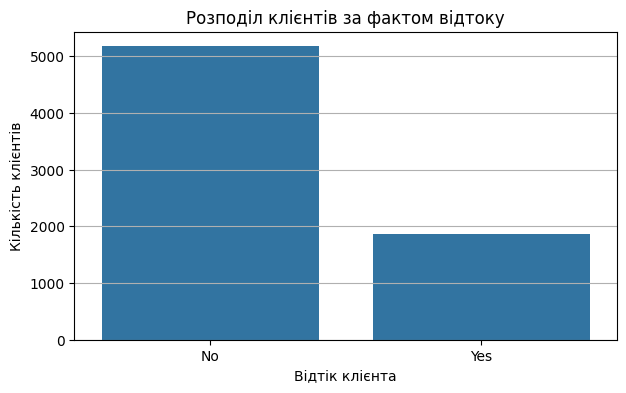

In [ ]:
print('Кількість клієнтів за класами:')
display(df['Churn'].value_counts())

print('\\nЧастка клієнтів за класами (%):')
display((df['Churn'].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Churn')
plt.title('Розподіл клієнтів за фактом відтоку')
plt.xlabel('Відтік клієнта')
plt.ylabel('Кількість клієнтів')
plt.grid(axis='y')
plt.show()

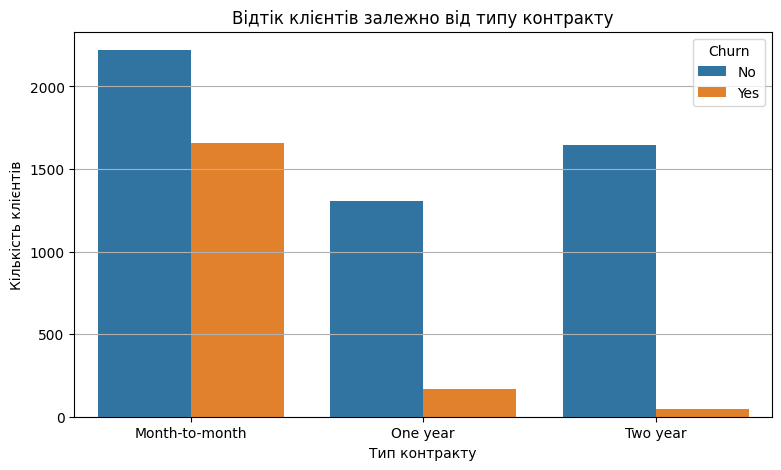

In [ ]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('Відтік клієнтів залежно від типу контракту')
plt.xlabel('Тип контракту')
plt.ylabel('Кількість клієнтів')
plt.grid(axis='y')
plt.show()

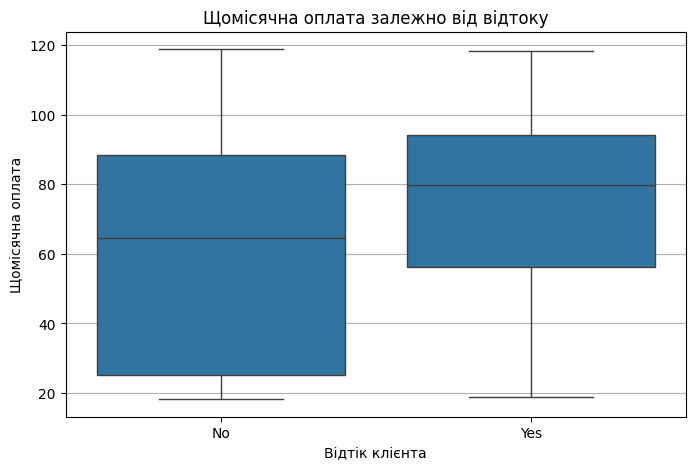

In [ ]:
df['MonthlyCharges'] = pd.to_numeric(df['MonthlyCharges'], errors='coerce')

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title('Щомісячна оплата залежно від відтоку')
plt.xlabel('Відтік клієнта')
plt.ylabel('Щомісячна оплата')
plt.grid(axis='y')
plt.show()

## 4. Підготовка даних


In [ ]:
data = df.copy()

data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')

data['Churn'] = data['Churn'].map({'No': 0, 'Yes': 1})

data = data.drop(columns=['customerID'], errors='ignore')

print('Пропущені значення після перетворення:')
display(data.isnull().sum())

print('\\nТипи даних:')
display(data.dtypes)

Пропущені значення після перетворення:


,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


\nТипи даних:


,0
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object
OnlineBackup,object


In [ ]:
X = data.drop(columns=['Churn'])
y = data['Churn']

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'bool']).columns.tolist()

print('Числові ознаки:', numeric_features)
print('Категоріальні ознаки:', categorical_features)
print('Кількість ознак:', X.shape[1])

Числові ознаки: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Категоріальні ознаки: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Кількість ознак: 19


In [ ]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)



## 5. Розділення на навчальну та тестову вибірки


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Навчальна вибірка:', X_train.shape)
print('Тестова вибірка:', X_test.shape)

print('\\nРозподіл класів у навчальній вибірці:')
display(y_train.value_counts(normalize=True).round(3))

print('\\nРозподіл класів у тестовій вибірці:')
display(y_test.value_counts(normalize=True).round(3))

Навчальна вибірка: (5634, 19)
Тестова вибірка: (1409, 19)
\nРозподіл класів у навчальній вибірці:


,proportion
Churn,
0,0.735
1,0.265


\nРозподіл класів у тестовій вибірці:


,proportion
Churn,
0,0.735
1,0.265


## 6. Побудова та порівняння моделей


In [ ]:
models_dict = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ),
    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),
    'Extra Trees': ExtraTreesClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
}

pipelines = {
    name: Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    for name, model in models_dict.items()
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

cv_results = []

for name, pipeline in pipelines.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1-score': scores['test_f1'].mean(),
        'ROC-AUC': scores['test_roc_auc'].mean()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(
    by='F1-score',
    ascending=False
).reset_index(drop=True)

print('Порівняння моделей за результатами крос-валідації:')
display(cv_results_df.round(4))

Порівняння моделей за результатами крос-валідації:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.7481,0.5165,0.8013,0.6279,0.8459
1,Random Forest,0.7861,0.6287,0.4749,0.5408,0.8212
2,Extra Trees,0.7691,0.5817,0.4622,0.5150,0.7878
3,Decision Tree,0.7405,0.5115,0.4997,0.5053,0.6638


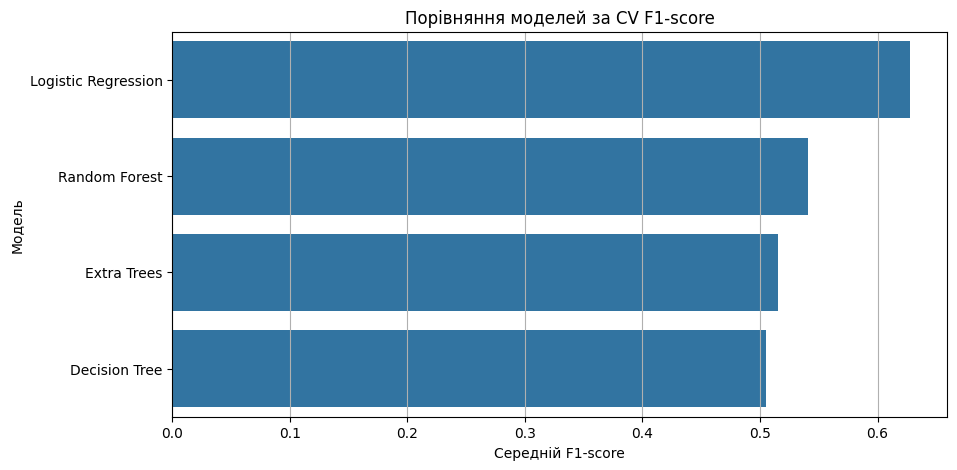

Найкраща початкова модель за CV F1-score: Logistic Regression


In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=cv_results_df, x='F1-score', y='Model')
plt.title('Порівняння моделей за CV F1-score')
plt.xlabel('Середній F1-score')
plt.ylabel('Модель')
plt.grid(axis='x')
plt.show()

best_initial_name = cv_results_df.iloc[0]['Model']
print('Найкраща початкова модель за CV F1-score:', best_initial_name)

## 7. Добір гіперпараметрів


In [ ]:
param_grids = {
    'Logistic Regression': {
        'classifier__C': [0.1, 1.0, 10.0],
        'classifier__solver': ['liblinear']
    },
    'Decision Tree': {
        'classifier__max_depth': [3, 5, 8, None],
        'classifier__min_samples_split': [2, 10, 20],
        'classifier__min_samples_leaf': [1, 5, 10]
    },
    'Random Forest': {
        'classifier__n_estimators': [150, 250],
        'classifier__max_depth': [None, 10, 20],
        'classifier__min_samples_leaf': [1, 3],
        'classifier__max_features': ['sqrt', 0.8]
    },
    'Extra Trees': {
        'classifier__n_estimators': [150, 250],
        'classifier__max_depth': [None, 10, 20],
        'classifier__min_samples_leaf': [1, 3],
        'classifier__max_features': ['sqrt', 0.8]
    }
}

selected_pipeline = pipelines[best_initial_name]
selected_grid = param_grids[best_initial_name]

print('Модель для налаштування:', best_initial_name)
print('Параметри для пошуку:', selected_grid)

Модель для налаштування: Logistic Regression
Параметри для пошуку: {'classifier__C': [0.1, 1.0, 10.0], 'classifier__solver': ['liblinear']}


In [ ]:
grid_search = GridSearchCV(
    estimator=selected_pipeline,
    param_grid=selected_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print('Найкращі параметри:')
print(grid_search.best_params_)

print('\\nНайкращий середній CV F1-score:')
print(grid_search.best_score_)

Fitting 5 folds for each of 3 candidates, totalling 15 fits
Найкращі параметри:
{'classifier__C': 0.1, 'classifier__solver': 'liblinear'}
\nНайкращий середній CV F1-score:
0.6292713727509


In [ ]:
best_model = grid_search.best_estimator_

print('Найкраща модель після налаштування:')
print(best_model)

Найкраща модель після налаштування:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('e

## 8. Фінальне оцінювання на тестовій вибірці


In [ ]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

test_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall': recall_score(y_test, y_pred, zero_division=0),
    'F1-score': f1_score(y_test, y_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_proba)
}

print('Результати найкращої моделі на тестовій вибірці:')
for metric, value in test_metrics.items():
    print(f'{metric}: {value:.4f}')

print('\\nКласифікаційний звіт:')
print(classification_report(
    y_test,
    y_pred,
    target_names=['Залишився (No)', 'Пішов (Yes)'],
    zero_division=0
))

Результати найкращої моделі на тестовій вибірці:
Accuracy: 0.7417
Precision: 0.5087
Recall: 0.7861
F1-score: 0.6176
ROC-AUC: 0.8408
\nКласифікаційний звіт:
                precision    recall  f1-score   support

Залишився (No)       0.90      0.73      0.80      1035
   Пішов (Yes)       0.51      0.79      0.62       374

      accuracy                           0.74      1409
     macro avg       0.71      0.76      0.71      1409
  weighted avg       0.80      0.74      0.76      1409



## 9. Аналіз важливості ознак


In [ ]:
classifier = best_model.named_steps['classifier']
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()

if hasattr(classifier, 'feature_importances_'):
    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': classifier.feature_importances_
    }).sort_values('Importance', ascending=False).head(15)

    display(importance_df)

    plt.figure(figsize=(10, 6))
    sns.barplot(data=importance_df, x='Importance', y='Feature')
    plt.title('15 найважливіших ознак')
    plt.xlabel('Важливість')
    plt.ylabel('Ознака')
    plt.grid(axis='x')
    plt.show()
else:
    print('Обрана модель не має вбудованого показника feature_importances_.')

Обрана модель не має вбудованого показника feature_importances_.


## 10. Прогноз відтоку для нового клієнта


In [ ]:
new_customer = {
    'gender': 'Female',
    'SeniorCitizen': 0,
    'Partner': 'Yes',
    'Dependents': 'No',
    'tenure': 12,
    'PhoneService': 'Yes',
    'MultipleLines': 'No',
    'InternetService': 'Fiber optic',
    'OnlineSecurity': 'No',
    'OnlineBackup': 'No',
    'DeviceProtection': 'No',
    'TechSupport': 'No',
    'StreamingTV': 'Yes',
    'StreamingMovies': 'Yes',
    'Contract': 'Month-to-month',
    'PaperlessBilling': 'Yes',
    'PaymentMethod': 'Electronic check',
    'MonthlyCharges': 85.50,
    'TotalCharges': 1026.00
}

new_customer_df = pd.DataFrame([new_customer])

new_customer_df = new_customer_df.reindex(columns=X.columns)

customer_prediction = best_model.predict(new_customer_df)[0]
customer_probability = best_model.predict_proba(new_customer_df)[0, 1]

print('Результат прогнозування:')
print('Ймовірність відтоку:', f'{customer_probability:.2%}')

if customer_prediction == 1:
    print('Прогноз: клієнт може піти (Churn = Yes)')
else:
    print('Прогноз: клієнт, імовірно, залишиться (Churn = No)')

Результат прогнозування:
Ймовірність відтоку: 87.72%
Прогноз: клієнт може піти (Churn = Yes)


## 11. Порівняння результатів та висновки


In [ ]:
initial_model = pipelines[best_initial_name]
initial_model.fit(X_train, y_train)

initial_pred = initial_model.predict(X_test)
initial_proba = initial_model.predict_proba(X_test)[:, 1]

comparison_df = pd.DataFrame([
    {
        'Model': best_initial_name + ' (початкова)',
        'Accuracy': accuracy_score(y_test, initial_pred),
        'Precision': precision_score(y_test, initial_pred, zero_division=0),
        'Recall': recall_score(y_test, initial_pred, zero_division=0),
        'F1-score': f1_score(y_test, initial_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, initial_proba)
    },
    {
        'Model': best_initial_name + ' (після GridSearchCV)',
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    }
])

print('Порівняння початкової та налаштованої моделей:')
display(comparison_df.round(4))

Порівняння початкової та налаштованої моделей:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression (початкова),0.7381,0.5043,0.7834,0.6136,0.8413
1,Logistic Regression (після GridSearchCV),0.7417,0.5087,0.7861,0.6176,0.8408


**Висновок:**
1. У роботі використано набір Telco Customer Churn, який містить характеристики клієнтів, підключені послуги, типи контрактів та інформацію про платежі.
2. За результатами крос-валідації для подальшого налаштування було обрано модель Logistic Regression.
3. Після налаштування модель отримала на тестовій вибірці Accuracy = 0.7417, Recall = 0.7861, F1-score = 0.6176 та ROC-AUC = 0.8408.
4. Підбір гіперпараметрів покращив F1-score порівняно з початковою моделлю (початковий F1-score = 0.6136, після налаштування = 0.6176).
5. Отриману модель можна використовувати для виявлення клієнтів із високим ризиком відтоку та своєчасного планування заходів для їх утримання.